In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from pathlib import Path

PROC = Path("../data/processed")
FIG  = Path("../results/figures"); FIG.mkdir(parents=True, exist_ok=True)
TAB  = Path("../results/tables");  TAB.mkdir(parents=True, exist_ok=True)

meta = pd.read_csv(PROC / "meta_clean.csv")
SUB_ORDER = ["LumA", "LumB", "Her2", "Basal", "Normal"]
PALETTE   = dict(zip(SUB_ORDER, ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974"]))
STAGES    = ["Stage I", "Stage II", "Stage III", "Stage IV"]
sns.set_theme(style="whitegrid", font_scale=1.05)

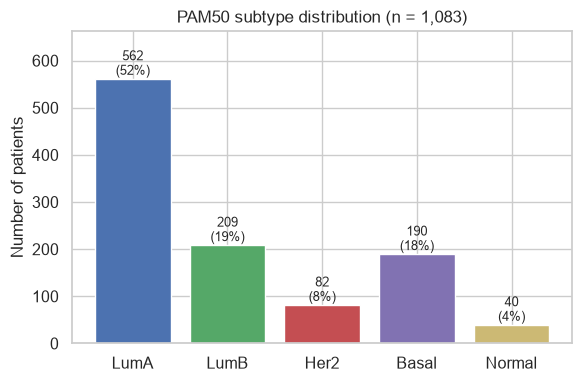

In [ ]:
# 1. Subtype distribution (class balance) 
vc = meta["subtype"].value_counts().reindex(SUB_ORDER)
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(vc.index, vc.values, color=[PALETTE[s] for s in vc.index])
for i, v in enumerate(vc.values):
    ax.text(i, v + 8, f"{v}\n({v / vc.sum():.0%})", ha="center", fontsize=9)
ax.set(title="PAM50 subtype distribution (n = 1,083)", ylabel="Number of patients", ylim=(0, vc.max() * 1.18))
plt.tight_layout(); plt.savefig(FIG / "03_subtype_distribution.png", dpi=200); plt.show()

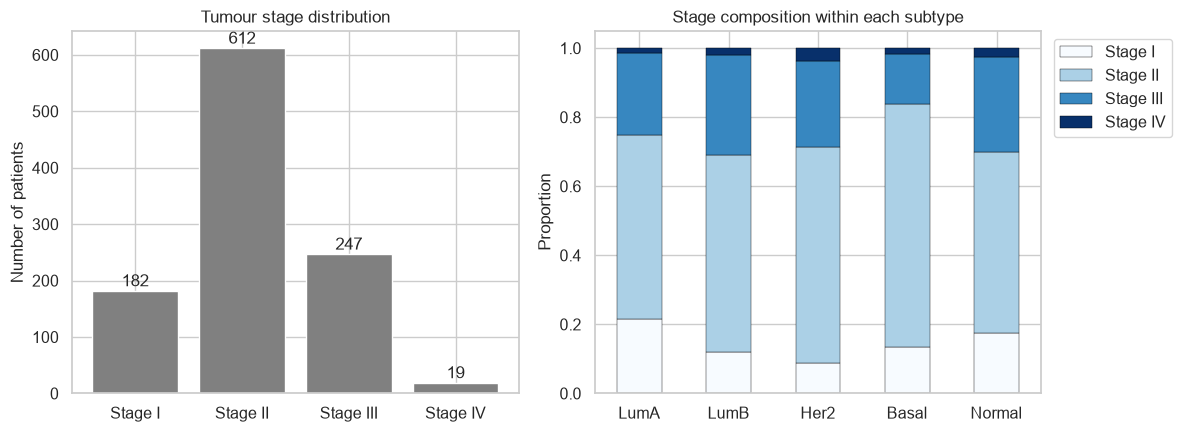

In [ ]:
#  2. Stage: overall and by subtype 
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sc = meta["stage_group"].value_counts().reindex(STAGES)
axes[0].bar(sc.index, sc.values, color="grey")

for i, v in enumerate(sc.values):
    axes[0].text(i, v + 8, str(v), ha="center")
    
axes[0].set(title="Tumour stage distribution", ylabel="Number of patients")

st = pd.crosstab(meta["subtype"], meta["stage_group"], normalize="index").reindex(index=SUB_ORDER, columns=STAGES)
st.plot(kind="bar", stacked=True, ax=axes[1], colormap="Blues", edgecolor="black", linewidth=0.3)
axes[1].set(title="Stage composition within each subtype", ylabel="Proportion", xlabel="")
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(FIG / "03_stage_distribution.png", dpi=200); plt.show()

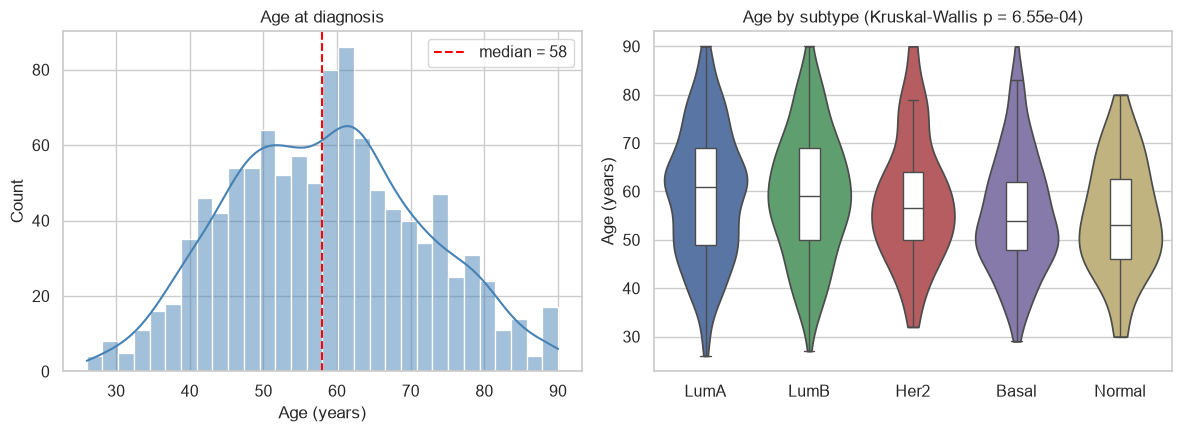

In [ ]:
# 3. Age: distribution and by subtype (violin + box) 
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(meta["age"], bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].axvline(meta["age"].median(), color="red", ls="--", label=f"median = {meta['age'].median():.0f}")
axes[0].set(title="Age at diagnosis", xlabel="Age (years)"); axes[0].legend()

sns.violinplot(data=meta, x="subtype", y="age", order=SUB_ORDER, hue="subtype", palette=PALETTE,
               inner=None, cut=0, ax=axes[1], legend=False)
sns.boxplot(data=meta, x="subtype", y="age", order=SUB_ORDER, width=0.2, ax=axes[1],
            boxprops=dict(facecolor="white", zorder=2), showfliers=False)
kw = stats.kruskal(*[g["age"].dropna() for _, g in meta.groupby("subtype")])
axes[1].set(title=f"Age by subtype (Kruskal-Wallis p = {kw.pvalue:.2e})", xlabel="", ylabel="Age (years)")
plt.tight_layout(); plt.savefig(FIG / "03_age.png", dpi=200); plt.show()

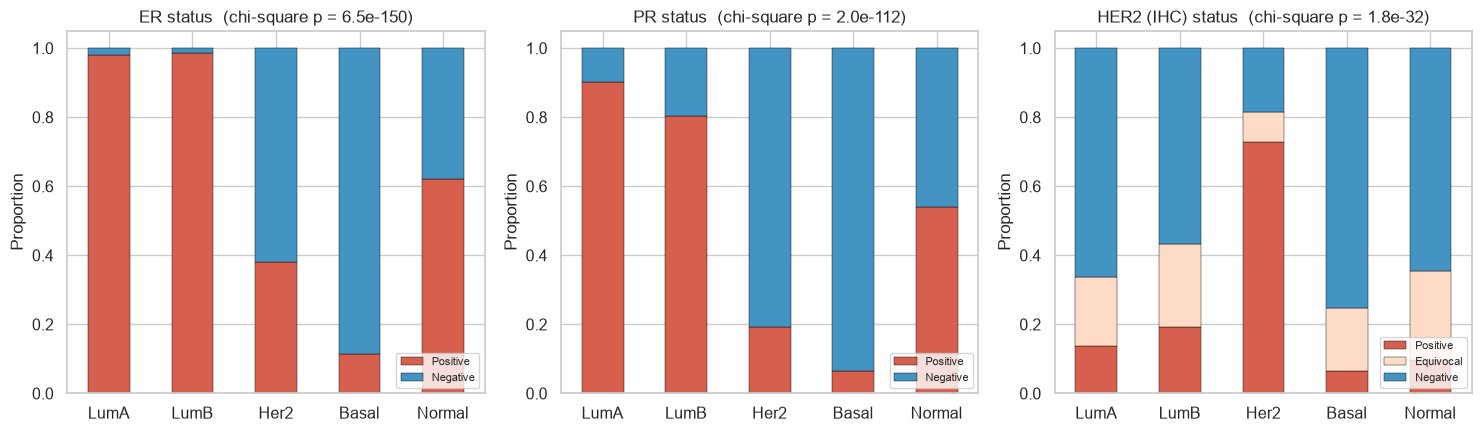

In [ ]:
#  4. Receptor status by subtype
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, col in zip(axes, ["ER", "PR", "HER2_IHC"]):
    ct = pd.crosstab(meta["subtype"], meta[col])
    p = stats.chi2_contingency(ct)[1]
    prop = ct.div(ct.sum(axis=1), axis=0).reindex(SUB_ORDER)
    cols = [c for c in ["Positive", "Equivocal", "Negative"] if c in prop.columns]
    prop[cols].plot(kind="bar", stacked=True, ax=ax, edgecolor="black", linewidth=0.3,
                    color={"Positive": "#d6604d", "Equivocal": "#000000", "Negative": "#4393c3"})
    ax.set(title=f"{col.replace('_IHC', ' (IHC)')} status  (chi-square p = {p:.1e})", xlabel="", ylabel="Proportion")
    ax.tick_params(axis="x", rotation=0); ax.legend(fontsize=8, loc="lower right")
    
plt.tight_layout(); plt.savefig(FIG / "03_receptor_status.png", dpi=200); plt.show()

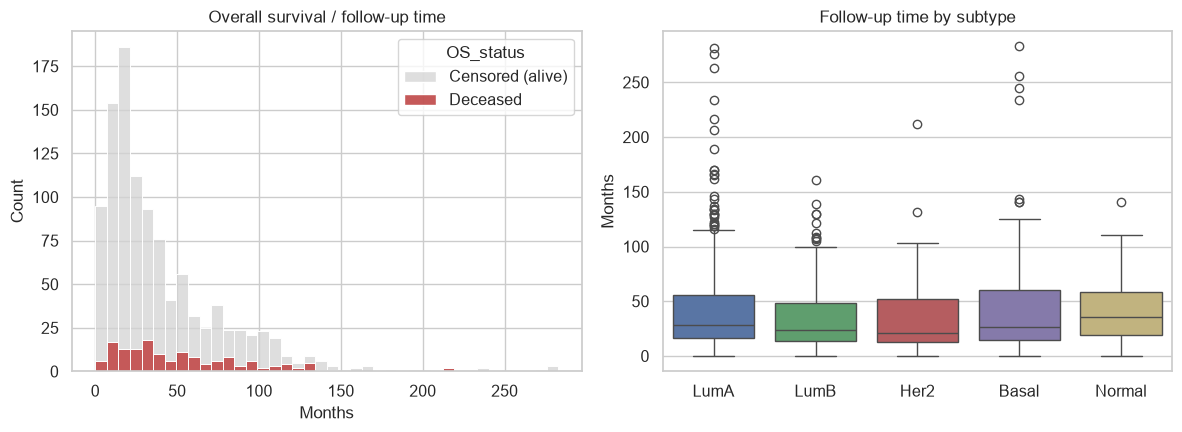

In [ ]:
# 5. Survival time and events
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

meta["OS_status"] = meta["OS_event"].map({0: "Censored (alive)", 1: "Deceased"})
sns.histplot(data=meta, x="OS_months", hue="OS_status", bins=40, multiple="stack", ax=axes[0],
             palette={"Censored (alive)": "lightgrey", "Deceased": "firebrick"})
axes[0].set(title="Overall survival / follow-up time", xlabel="Months")
sns.boxplot(data=meta, x="subtype", y="OS_months", order=SUB_ORDER, hue="subtype", palette=PALETTE,
            ax=axes[1], legend=False)
axes[1].set(title="Follow-up time by subtype", xlabel="", ylabel="Months")
plt.tight_layout(); plt.savefig(FIG / "03_survival_time.png", dpi=200); plt.show()

In [ ]:
#  6. Summary table ("Table 1") and statistical tests 
rows = []
for s in SUB_ORDER + ["All"]:
    d = meta if s == "All" else meta[meta["subtype"] == s]
    rows.append({
        "Subtype": s, "n": len(d),
        "Age, median (IQR)": f"{d['age'].median():.0f} ({d['age'].quantile(.25):.0f}-{d['age'].quantile(.75):.0f})",
        "Stage III-IV %": f"{d['stage_group'].isin(['Stage III', 'Stage IV']).sum() / d['stage_group'].notna().sum():.1%}",
        "ER+ %": f"{(d['ER'] == 'Positive').sum() / d['ER'].notna().sum():.1%}",
        "PR+ %": f"{(d['PR'] == 'Positive').sum() / d['PR'].notna().sum():.1%}",
        "HER2+ (IHC) %": f"{(d['HER2_IHC'] == 'Positive').sum() / d['HER2_IHC'].notna().sum():.1%}",
        "Deaths": int(d["OS_event"].sum()),
        "Median follow-up (mo)": f"{d['OS_months'].median():.1f}",
    })
    
table1 = pd.DataFrame(rows).set_index("Subtype")
table1.to_csv(TAB / "03_clinical_summary.csv")
print(table1.to_string())

tests = [("Age vs subtype", "Kruskal-Wallis", kw.pvalue)]
for col in ["stage_group", "ER", "PR", "HER2_IHC"]:
    tests.append((f"{col} vs subtype", "Chi-square",
                  stats.chi2_contingency(pd.crosstab(meta["subtype"], meta[col]))[1]))
tests = pd.DataFrame(tests, columns=["Comparison", "Test", "p-value"])
tests.to_csv(TAB / "03_clinical_tests.csv", index=False)
print("\n", tests.to_string(index=False))

            n Age, median (IQR) Stage III-IV %  ER+ %  PR+ % HER2+ (IHC) %  Deaths Median follow-up (mo)
Subtype                                                                                                 
LumA      562        61 (49-69)          25.0%  98.0%  90.1%         13.7%      66                  28.4
LumB      209        59 (50-69)          31.1%  98.5%  80.2%         19.3%      33                  23.9
Her2       82        56 (50-64)          28.7%  38.2%  19.2%         72.9%      17                  21.4
Basal     190        54 (48-62)          16.0%  11.5%   6.6%          6.4%      27                  26.9
Normal     40        53 (46-62)          30.0%  62.2%  54.1%          9.7%       7                  35.4
All      1083        58 (49-67)          25.1%  77.0%  66.9%         18.0%     150                  27.0

             Comparison           Test       p-value
        Age vs subtype Kruskal-Wallis  6.550956e-04
stage_group vs subtype     Chi-square  7.477021e-04
  